# Reweighting along $\varepsilon_{go}$

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
from tqdm import tqdm
from matplotlib import pyplot as plt

while os.path.split(os.getcwd())[-1] != 'calvados-slim':
    os.chdir('..')

from src import utils, visualisation
from src.analysis import mbar, slim

In [2]:
# --- Inputs ---
dGs = pd.read_csv('data/analysis/dGs.csv')
q_bounds = pd.read_csv('data/analysis/Q_bounds_calibrated.csv', index_col=0).iloc[:, 0]

# --- Configuration ---
TEMPERATURE  = 298.15
STRIDE       = 10                                   # frame subsampling (decorrelation + speed)
GRID         = np.round(np.arange(0.0, 8.001, 0.05), 2)

KD_WINDOW    = (1e-8, 1e-2)
DG_WINDOW    = tuple(np.sort(slim.dG(np.array(KD_WINDOW))))

# candidate selection
N_CANDIDATES = 10                                   # proposed eps_go per system
MIN_SPACING  = 0.1                                  # min gap between proposed eps_go
EXCLUDE_TOL  = MIN_SPACING                          # keep proposals off already-simulated eps_go

# error bars & reliability
ERRORS       = 'bootstrap'                          # 'bootstrap' (default, correlation-aware) or 'delta' -- interchangeable
N_BOOT       = 100                                  # bootstrap replicates (dominates runtime; lower for a quick pass)
BLOCK_SIZE   = 1                                    # STRIDE already decorrelates; raise to ~2*tau for raw frames
SEED         = 0
MIN_N_EFF_MINOR  = 5.0                                  # eff. samples of the rarer state for 'reliable'
MIN_NEFF     = 50.0

systems = sorted(dGs.System.unique())

print(f'{len(systems)} systems | dG window {DG_WINDOW[0]:.1f}..{DG_WINDOW[1]:.1f} kJ/mol '
      f'(Kd {KD_WINDOW[0]:.0e} to {KD_WINDOW[1]:.0e} M) | errors={ERRORS}')

276 systems | dG window -45.7..-11.4 kJ/mol (Kd 1e-08 to 1e-02 M) | errors=bootstrap


## Reweight each system's scans along $\varepsilon_{go}$

Pool the converged states, build MBAR, and reweight onto the fine grid.
`N_eff_minor = N_eff · min(f, 1−f)` is the effective sample size of the *rarer* state — it collapses
in overlap gaps and at censored edges, and is the basis for both the value score and the reliability flag.

In [3]:
# Getting sim dirs
sims = utils.get_sim_dirs()
sims['Frames'] = (sims.Path + '/' + sims.System + '.dcd').map(utils.get_dcd_frame_count)

# Filtering for unrun or too short simulations
sims = sims[sims['Frames'] > 100]
sims

,System,eps_go,Sampling mode,Replicate,Path,Frames
0,afadin-bcr,0.0,Scan,1,./sim/afadin-bcr/eps_go=0.00/scan/rep1,10000.0
1,afadin-bcr,1.0,Scan,1,./sim/afadin-bcr/eps_go=1.00/scan/rep1,10000.0
2,afadin-bcr,2.0,Scan,1,./sim/afadin-bcr/eps_go=2.00/scan/rep1,10000.0
3,afadin-bcr,3.0,Scan,1,./sim/afadin-bcr/eps_go=3.00/scan/rep1,10000.0
4,afadin-bcr,4.0,Scan,1,./sim/afadin-bcr/eps_go=4.00/scan/rep1,10000.0
...,...,...,...,...,...,...
2803,ywhab-mlxipl,1.0,Scan,1,./sim/ywhab-mlxipl/eps_go=1.00/scan/rep1,10000.0
2804,ywhab-mlxipl,2.0,Scan,1,./sim/ywhab-mlxipl/eps_go=2.00/scan/rep1,10000.0
2805,ywhab-mlxipl,3.0,Scan,1,./sim/ywhab-mlxipl/eps_go=3.00/scan/rep1,10000.0
2806,ywhab-mlxipl,4.0,Scan,1,./sim/ywhab-mlxipl/eps_go=4.00/scan/rep1,10000.0


In [5]:
from concurrent.futures import ProcessPoolExecutor, as_completed

N_WORKERS = max(1, (os.cpu_count() or 1) - 1)

dGs_reweighted = {}
to_run = {}
for system_id, dGs_subset in dGs.groupby('System'):

    # Not treating mono state trajectories as converged
    to_run[system_id] = dGs_subset[~dGs_subset.traj_never_binds & ~dGs_subset.traj_never_unbinds]

with ProcessPoolExecutor(max_workers=N_WORKERS) as executor:
    futures = {
        executor.submit(
            mbar.reweight_system, system_id, dGs_subset, sims, q_bounds[system_id], GRID,
            stride=STRIDE, temperature=TEMPERATURE, errors=ERRORS, n_boot=N_BOOT, block_size=BLOCK_SIZE, seed=SEED,
        ): system_id
        for system_id, dGs_subset in to_run.items()
    }
    for future in tqdm(as_completed(futures), total=len(futures)):
        dGs_reweighted[futures[future]] = future.result()

dGs_reweighted = pd.concat(dGs_reweighted).reset_index(level=1, drop=True)
dGs_reweighted.index.name = 'System'
dGs_reweighted = dGs_reweighted.sort_index(kind='stable')  # deterministic row order (completion order is not)

dGs_reweighted.to_csv('data/analysis/dGs_reweighted.csv')

100%|██████████| 276/276 [02:56<00:00,  1.57it/s]


([<matplotlib.axis.XTick at 0x16feb5e40>,
 [Text(0, 0, '0'),
  Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9'),
  Text(10, 0, '10')])

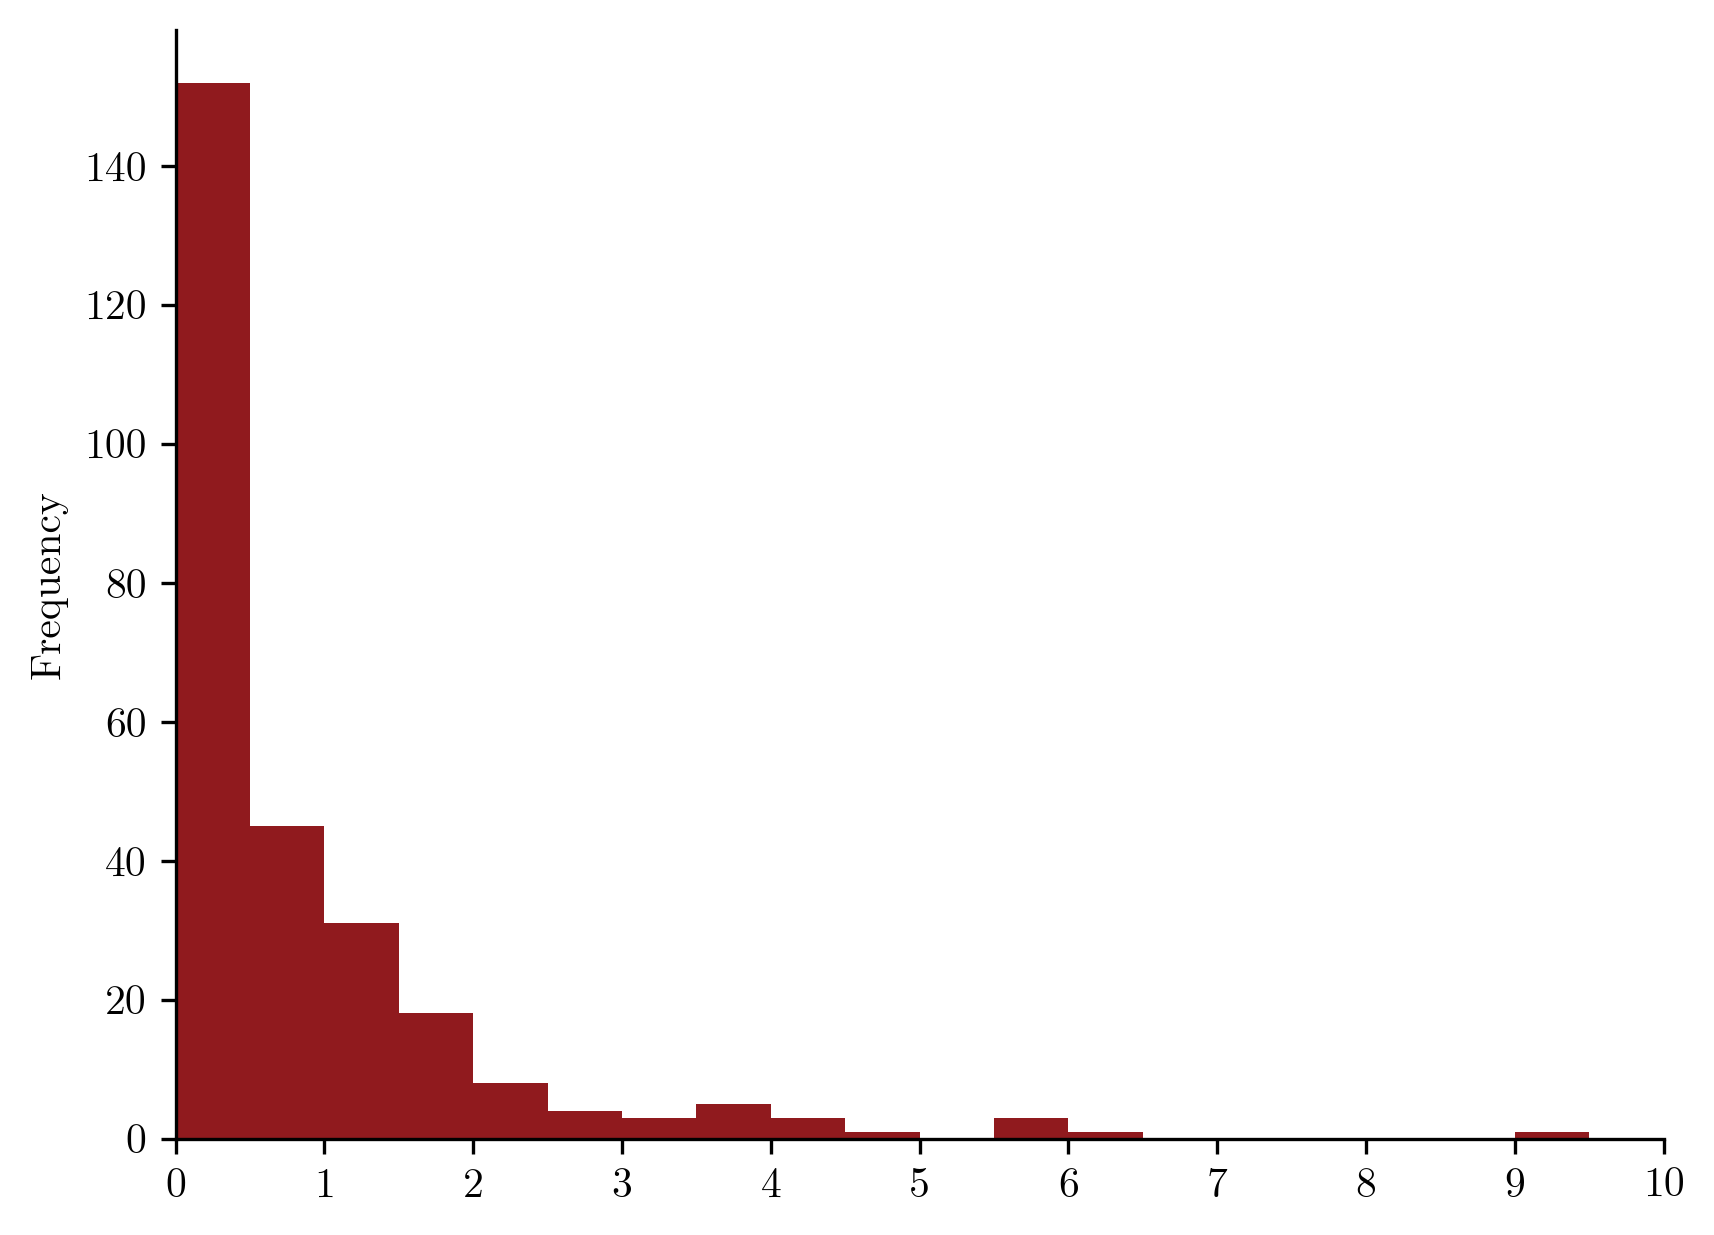

In [6]:
# RMSD after refinement
dGs_reweighted = pd.read_csv('data/analysis/dGs_reweighted.csv', index_col=0)
dGs_reweighted_unrefined = pd.read_csv('data/analysis/dGs_reweighted_unrefined.csv', index_col=0)
(
    (dGs_reweighted - dGs_reweighted_unrefined)
    [(dGs_reweighted_unrefined.dG >= DG_WINDOW[0]) & (dGs_reweighted_unrefined.dG <= DG_WINDOW[1])]
    .groupby('System')
    .apply(lambda sub: 
           (
               sub['dG'][np.isfinite(sub['dG'])]
            **2)
            .sum()
            **0.5)
    .sort_values()
    .plot.hist(bins=np.arange(0,10,0.5))
)
plt.xlim(0)
plt.xticks(np.arange(0,11,1))

## Determining most valuable refinement simulation candidates

Surviving candidates are ranked by the **information gap**

$$N_\text{eff}^\text{minor} = N_\text{eff}\cdot\min(f,\,1-f),$$

In [7]:
# Prioritising candidates for refinement simulations
refinement_priority = []

for system_id, candidates in tqdm(dGs_reweighted.groupby(level=0)):

    # Determining existing simulations
    existing = dGs[dGs['System'] == system_id]
    eps_go_lower_limit = existing[existing.traj_transitions == 0].eps_go.max() if (existing.traj_transitions == 0).any() else np.inf
    eps_go_upper_limit = existing[existing.traj_transitions == 1].eps_go.min() if (existing.traj_transitions == 1).any() else -np.inf

    # Only candidates within affinity window of interest
    candidates = candidates[(candidates.dG >= DG_WINDOW[0]) & (candidates.dG <= DG_WINDOW[1])]
    candidates.rename({'dG': 'dG_pred', 'dG_sigma': 'dG_pred_sigma'}, axis=1, inplace=True)

    # See if any candidates remain
    if len(candidates) == 0:
        continue

    # Loop over candidates descendingly
    picked = [] 
    for _, candidate in candidates.sort_values('N_eff_minor', ascending=True).iterrows():

        # Checking if too close to existing
        if any(abs(candidate.eps_go - e) < EXCLUDE_TOL for e in existing.eps_go):  continue

        # Check if expected not to converge
        if candidate.eps_go > eps_go_upper_limit:  continue
        if candidate.eps_go < eps_go_lower_limit:  continue

        # Checking if too close to previous pick
        if any(abs(candidate.eps_go - p) < MIN_SPACING for p in picked):    continue

        picked.append(candidate.eps_go)

        if len(picked) >= N_CANDIDATES: break

    picked = candidates[candidates.eps_go.isin(picked)]
    refinement_priority.append(picked)

refinement_priority = pd.concat(refinement_priority)
refinement_priority.sort_values('N_eff_minor', ascending=True, na_position='last', inplace=True)
refinement_priority.reset_index(inplace=True)

refinement_priority.to_csv('data/planning/refinement_priority.csv', index=False)


  0%|          | 0/276 [00:00<?, ?it/s]/var/folders/ls/l5m3kcsd4lddcv2284nfc4b40000gn/T/ipykernel_68726/1504069805.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  candidates.rename({'dG': 'dG_pred', 'dG_sigma': 'dG_pred_sigma'}, axis=1, inplace=True)
100%|██████████| 276/276 [00:00<00:00, 614.55it/s]


## Plotting

In [8]:
for system_id, reweighted_subset in tqdm(dGs_reweighted.groupby('System')):

    # Simulations
    dGs_system = dGs[dGs['System'] == system_id]
    dGs_converged = dGs_system[~dGs_system.traj_never_binds & ~dGs_system.traj_never_unbinds]
    dGs_unconverged = dGs_system[dGs_system.traj_never_binds | dGs_system.traj_never_unbinds]
    plt.errorbar(
        dGs_converged['eps_go'],
        dGs_converged['dG'],
        np.stack([dGs_converged['dG'] - dGs_converged['dG-1SEM'],  dGs_converged['dG+1SEM'] - dGs_converged['dG']]),
        color=visualisation.ku_red, ms=2, capsize=1, elinewidth=0.5, linewidth=0.5, fmt = 's', 
        label="Trajectory estimate"
    )
    plt.scatter(
        dGs_unconverged['eps_go'],
        np.where(dGs_unconverged['dG'] == np.inf, 0, dGs_unconverged['dG']),
        marker='x', c='red', s=15,
        label="Completely bound/unbound trajectory"
    )

    # Reweighting
    reweighted_subset = reweighted_subset[reweighted_subset['dG'] > -70]
    reweighted_subset_reliable = reweighted_subset[(reweighted_subset.N_eff_minor >= MIN_N_EFF_MINOR) & (reweighted_subset.N_eff >= MIN_NEFF)]
    plt.plot(
        reweighted_subset_reliable['eps_go'],
        reweighted_subset_reliable['dG'],
        alpha=1, c=visualisation.ku_red, lw=.5,
        label="Reliable reweighting"
    )
    plt.plot(
        reweighted_subset['eps_go'],
        reweighted_subset['dG'],
        alpha=0.8, ls='dotted', c=visualisation.ku_red, lw=.5,
        label="Unreliable reweighting"
    )
    plt.fill_between(
        reweighted_subset['eps_go'].values,
        (reweighted_subset['dG'] - reweighted_subset['dG_sigma']).values,
        (reweighted_subset['dG'] + reweighted_subset['dG_sigma']).values,
        alpha=0.2,
        label="Reweighting SEM (bootstrap)"
    )


    # SLiM range
    xlim = plt.xlim()
    plt.axhspan(*DG_WINDOW, color=visualisation.light_green, alpha=0.2, label=r"ΔG°-range for $K_d$ = 10 mM to 10 nM")
    for Kd in np.geomspace(1,1e-12,13):
        dG = slim.dG(Kd)
        if (dG >= DG_WINDOW[0]) & (dG <= DG_WINDOW[-1]):
            plt.axhline(dG, *xlim, color=visualisation.light_green, alpha=0.5, ls='dashed', lw=.5)

    # Decorations
    ylim = plt.ylim(-70,10)
    plt.ylabel(r'SLiM Affinity ΔG° [kJ/mol]')
    plt.xlabel(r'$\text{G}\bar{\text{o}}$ potential well depth $\varepsilon_{\text{G}\bar{\text{o}}}$ [kJ/mol]')
    plt.yticks(np.arange(ylim[0],ylim[1]+.1,5),minor=False)
    plt.yticks(np.arange(ylim[0],ylim[1]+.1,1),minor=True)
    plt.grid(which='major', alpha=0.3, linewidth=0.5)
    plt.grid(which='minor', alpha=0.1, linewidth=0.2)
    handles, labels = plt.gca().get_legend_handles_labels()
    order = [5,0,4,1,2,3]
    plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order],
               frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5,-0.15))
    plt.title(f'{system_id}')
    #plt.show()
    plt.savefig(f'figs/reweightings/{system_id}.png', bbox_inches='tight')
    plt.clf()
    
    

100%|██████████| 276/276 [01:01<00:00,  4.47it/s]


<Figure size 1920x1440 with 0 Axes>